# 🧮 Light Linear Algebra: a table is a matrix

**Zero Grad · Data Analysis course · Foundations**

> 📖 **The lesson (in Arabic), with diagrams and interactive widgets:** [zero-grad.com/courses/da/linalg](https://zero-grad.com/courses/da/linalg/)
>
> 🗂️ **The data:** [NileCart Sales on Kaggle](https://www.kaggle.com/datasets/a7madmostafa/nilecart-sales)

This is the solved notebook of the *Light linear algebra* lesson.
No proofs and no formulas to memorise: just the few ideas that every data tool is built on, each one done on NileCart.

We use NumPy here, because it's the library that does linear algebra in Python.
The next lesson is all about NumPy, so for now read the code and look at what comes out.

| # | Part | The idea |
|---|---|---|
| 1 | Scalar, vector, matrix | A number, a list of numbers, a table of numbers |
| 2 | Vector arithmetic | Whole columns at once: `quantity * unit_price` |
| 3 | The dot product | Multiply, then add: a basket's total |
| 4 | A table as a matrix | Rows, columns, shape, transpose |
| 5 | Matrix multiplication | Many dot products at once, and the shape rule |

---
# 0️⃣ Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4)
pd.options.display.float_format = "{:,.2f}".format
np.set_printoptions(suppress=True, linewidth=110)

# On Kaggle the data lives under /kaggle/input, locally in the repo's data/ folder
on_kaggle = sorted(Path("/kaggle/input").glob("**/sales.csv"))
DATA = on_kaggle[0].parent if on_kaggle else Path("../../data")

sales = pd.read_csv(DATA / "sales.csv", parse_dates=["order_date"])
products = pd.read_csv(DATA / "products.csv")
done = sales[sales["status"] == "completed"]

---
# 1️⃣ Scalar, vector, matrix

Three words for three shapes of numbers:

| Name | What it is | NileCart example | `ndim` | `shape` |
|---|---|---|---|---|
| **Scalar** | one number | the VAT rate, 0.14 | 0 | `()` |
| **Vector** | a list of numbers | the `revenue` column | 1 | `(n,)` |
| **Matrix** | a table of numbers | `sales` with its number columns | 2 | `(rows, columns)` |

In [2]:
vat = np.array(0.14)
revenue = sales["revenue"].to_numpy()
X = sales[["quantity", "unit_price", "discount", "revenue", "profit"]].to_numpy()

for name, a in [("vat", vat), ("revenue", revenue), ("X", X)]:
    print(f"{name:8} ndim={a.ndim}  shape={a.shape}")

vat      ndim=0  shape=()
revenue  ndim=1  shape=(1466,)
X        ndim=2  shape=(1466, 5)


**A column is a vector** of 1,466 numbers, one per order line.
**A row is a vector too**: one order line, described by 5 numbers.

In [3]:
X[1]

array([     9.  ,  30400.  ,      0.05, 259920.  ,  15120.  ])

Row 1 is the order we met in the Introduction: 9 laptops at 30,400 EGP each, 5% discount, 259,920 EGP of revenue and 15,120 EGP of profit.

The order of the numbers matters. `X[1]` only makes sense because we know the columns are
`quantity, unit_price, discount, revenue, profit`, in that order.
A vector is an **ordered** list.

---
# 2️⃣ Vector arithmetic: whole columns at once

Two vectors of the same length can be added, subtracted, multiplied and divided **element by element**:
the first with the first, the second with the second, and so on.

That's how every derived column in NileCart was made:

In [4]:
q = sales["quantity"].to_numpy()
p = sales["unit_price"].to_numpy()
d = sales["discount"].to_numpy()

gross = q * p                    # element by element
rev = gross * (1 - d)

print(q[:4], "*", p[:4], "=", gross[:4])
print("same as the gross column:  ", np.allclose(gross, sales["gross"]))
print("same as the revenue column:", np.allclose(rev, sales["revenue"]))

[ 5.  9. 10.  5.] * [   63. 30400.    57.    60.] = [   315. 273600.    570.    300.]
same as the gross column:   True
same as the revenue column: True


No loop. One line works on all 1,466 rows.
The two vectors must have the **same length**: element 7 of `q` pairs with element 7 of `p`.

## 2.1 A vector and a scalar

A scalar meets every element of the vector. Adding 14% VAT to every order:

In [5]:
with_vat = rev * (1 + vat)
print(rev[:4])
print(with_vat[:4])

[   315. 259920.    570.    285.]
[   359.1 296308.8    649.8    324.9]


The same works for a currency. The last dollar rate in `fx_rates.csv`:

In [6]:
fx = pd.read_csv(DATA / "fx_rates.csv")
usd_egp = fx["usd_egp"].iloc[-1]
print("1 USD =", usd_egp, "EGP")
(rev / usd_egp)[:4].round(2)

1 USD = 48.98 EGP


array([   6.43, 5306.66,   11.64,    5.82])

Multiplying a vector by a scalar **scales** it: every element grows or shrinks by the same factor.

---
# 3️⃣ The dot product: multiply, then add

The **dot product** of two vectors of the same length:
multiply them element by element, then add everything up.

$$\mathbf{q} \cdot \mathbf{p} = q_1 p_1 + q_2 p_2 + \dots + q_n p_n$$

It's the most common calculation in data analysis, even when nobody calls it that.
A basket: a monitor, two keyboards, three mice and ten notebooks.

In [7]:
items = ["Monitor", "Keyboard", "Mouse", "Notebook"]
basket = np.array([1, 2, 3, 10])                                   # how many of each
price = products.set_index("product_name").loc[items, "list_price"].to_numpy()

print("quantities:", basket)
print("prices:    ", price)
print("products:  ", basket * price)
print("total:     ", basket @ price)                              # @ is the dot product

quantities: [ 1  2  3 10]
prices:     [7000 1200  450   60]
products:   [7000 2400 1350  600]
total:      11350


`basket @ price` is the dot product: the bill of the basket.

## 3.1 The whole table in one dot product

The quantity vector dotted with the price vector gives the gross value of **all** the orders:

In [8]:
print(f"q @ p           = {q @ p:,.0f}")
print(f"gross.sum()     = {sales['gross'].sum():,.0f}")

q @ p           = 29,267,670
gross.sum()     = 29,267,670


---
# 4️⃣ A table as a matrix

`X` from Part 1 is the number part of `sales` as a matrix: 1,466 rows and 5 columns.

In [9]:
cols = ["quantity", "unit_price", "discount", "revenue", "profit"]
print("shape:", X.shape)
X[:5]

shape: (1466, 5)


array([[     5.  ,     63.  ,      0.  ,    315.  ,    215.  ],
       [     9.  ,  30400.  ,      0.05, 259920.  ,  15120.  ],
       [    10.  ,     57.  ,      0.  ,    570.  ,    370.  ],
       [     5.  ,     60.  ,      0.05,    285.  ,    185.  ],
       [     4.  ,   1140.  ,      0.  ,   4560.  ,   2160.  ]])

## 4.1 Rows, columns, one cell

`X[i, j]` is row `i`, column `j`. A whole row is `X[i]`, a whole column is `X[:, j]`.

In [10]:
print("one cell, X[1, 3]: ", X[1, 3])                 # row 1, column 3 = revenue
print("one row, X[1]:     ", X[1])
print("one column, X[:, 3]:", X[:5, 3], "...")

one cell, X[1, 3]:  259920.0
one row, X[1]:      [     9.    30400.        0.05 259920.    15120.  ]
one column, X[:, 3]: [   315. 259920.    570.    285.   4560.] ...


## 4.2 Transpose

The **transpose** `X.T` turns rows into columns: shape `(1466, 5)` becomes `(5, 1466)`.

In [11]:
print(X.shape, "->", X.T.shape)

(1466, 5) -> (5, 1466)


## 4.3 Column sums are a matrix product

A vector of ones, multiplied by the matrix, adds up every column:

In [12]:
ones = np.ones(len(X))
pd.Series(ones @ X, index=cols)

quantity          5,990.00
unit_price    7,192,857.00
discount             72.90
revenue      27,841,022.95
profit        5,394,592.95
dtype: float64

In [13]:
sales[cols].sum()

quantity          5,990.00
unit_price    7,192,857.00
discount             72.90
revenue      27,841,022.95
profit        5,394,592.95
dtype: float64

Same numbers. Divide by the number of rows and you have the column means.
(A sum of prices or of discounts means nothing, but the calculation is the same for every column.)
`sum()` and `mean()` in Pandas are this calculation, done fast.

---
# 5️⃣ Matrix multiplication

A matrix times a vector is one dot product **per row**.
A matrix times a matrix is one dot product **per pair (row of the first, column of the second)**.

## 5.1 A matrix times a vector

The four Electronics products, units sold in each quarter of 2025 (completed orders):

In [14]:
elec = ["Laptop", "Phone", "Tablet", "Monitor"]
d25 = done[(done["order_date"].dt.year == 2025) & done["product_name"].isin(elec)]
Q = d25.pivot_table(index=d25["order_date"].dt.quarter, columns="product_name",
                    values="quantity", aggfunc="sum").reindex(columns=elec).astype(int)
Q.index = ["Q1", "Q2", "Q3", "Q4"]
Q

product_name,Laptop,Phone,Tablet,Monitor
Q1,17,44,34,43
Q2,6,33,17,32
Q3,10,17,43,41
Q4,37,77,61,49


`Q` is a 4 × 4 matrix: quarters × products. The list price is a vector of 4, one per product.
`Q @ price` dots every quarter's row with the prices: the sales of each quarter, at list price.

In [15]:
P = products.set_index("product_name").loc[elec, ["list_price", "unit_cost"]]
list_price = P["list_price"].to_numpy()

pd.Series(Q.to_numpy() @ list_price, index=Q.index, name="sales at list price")

Q1    2011000
Q2    1197000
Q3    1386000
Q4    3584000
Name: sales at list price, dtype: int64

Q4 sold the most by far: White Friday and New Year.

## 5.2 A matrix times a matrix

Put the price **and** the cost side by side: `P` is 4 products × 2 columns.
`Q @ P` does both dot products for every quarter at once:

In [16]:
P

,list_price,unit_cost
product_name,,
Laptop,32000,27200
Phone,18000,14600
Tablet,11000,9000
Monitor,7000,5700


In [17]:
QP = pd.DataFrame(Q.to_numpy() @ P.to_numpy(), index=Q.index, columns=["sales", "cost"])
QP["margin"] = QP["sales"] - QP["cost"]
QP

,sales,cost,margin
Q1,2011000,1655900,355100
Q2,1197000,980400,216600
Q3,1386000,1140900,245100
Q4,3584000,2958900,625100


Each cell of the result is one row of `Q` dotted with one column of `P`. Q4's sales, by hand:

In [18]:
print(Q.loc["Q4"].to_numpy(), "@", P["list_price"].to_numpy())
print(f"= {Q.loc['Q4'].to_numpy() @ P['list_price'].to_numpy():,.0f}")

[37 77 61 49] @ [32000 18000 11000  7000]
= 3,584,000


## 5.3 The shape rule

$$(m \times n) \; @ \; (n \times k) = (m \times k)$$

The **inside** numbers must match (the columns of the first = the rows of the second),
and the **outside** numbers give the shape of the result.

`Q` is (4 × 4) and `P` is (4 × 2), so `Q @ P` is (4 × 2). The other way round doesn't work:

In [19]:
print("Q:", Q.shape, " P:", P.shape, " Q @ P:", (Q.to_numpy() @ P.to_numpy()).shape)

try:
    P.to_numpy() @ Q.to_numpy()
except ValueError as e:
    print("P @ Q ->", e)

Q: (4, 4)  P: (4, 2)  Q @ P: (4, 2)
P @ Q -> matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 4 is different from 2)


(4 × **2**) @ (**4** × 4): the inside numbers are 2 and 4, they don't match.
Order matters in matrix multiplication: `A @ B` and `B @ A` are not the same thing, and often only one of them exists.

When you get a *shapes not aligned* error, print the two shapes and check the inside numbers.

## 5.4 The whole year

The same calculation on all 11 products and all 8 quarters of the two years: (8 × 11) @ (11 × 2).

Q: (8, 11)  P: (11, 2)


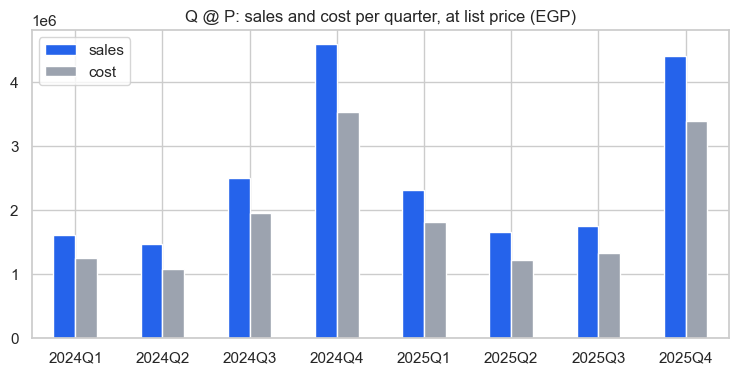

In [20]:
Qall = done.pivot_table(index=done["order_date"].dt.to_period("Q"), columns="product_name",
                        values="quantity", aggfunc="sum", fill_value=0)
Pall = products.set_index("product_name").loc[Qall.columns, ["list_price", "unit_cost"]]
print("Q:", Qall.shape, " P:", Pall.shape)

year = pd.DataFrame(Qall.to_numpy() @ Pall.to_numpy(), index=Qall.index.astype(str), columns=["sales", "cost"])
ax = year.plot(kind="bar", color=["#2563eb", "#9ca3af"], rot=0)
ax.set(title="Q @ P: sales and cost per quarter, at list price (EGP)", xlabel="")
plt.show()

Every Q4 towers over the other quarters. That's the November–December peak from the Introduction, now from one matrix product.

*At list price:* real revenue is a bit different, because prices moved ±5% and some orders had a discount.
`Q @ P` answers "how much would this have been at list price?", which is still a useful number for planning.

---
# 🧰 Summary

| Idea | In one line | NumPy |
|---|---|---|
| Scalar · vector · matrix | a number · a list · a table | `ndim`, `shape` |
| Element-wise | same length, first with first | `q * p` |
| Scalar × vector | every element, same factor | `rev * 1.14` |
| Dot product | multiply, then add | `q @ p` |
| A table as a matrix | rows × columns, `X[i, j]` | `df.to_numpy()` |
| Transpose | rows ↔ columns | `X.T` |
| Matrix product | a dot product per (row, column) | `Q @ P` |
| Shape rule | (m × **n**) @ (**n** × k) = (m × k) | |

**Next lesson:** NumPy: arrays, and computing on a whole column at once.

📚 All the lessons of the course: [zero-grad.com/courses/da](https://zero-grad.com/courses/da/)